# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

## How to run this completed notebook (local GPU)

Tested target: a local machine with an **NVIDIA RTX 5070 Ti (16 GB, Blackwell / sm_120)**. See `README.md` for the full setup.

1. Create an environment and install **PyTorch ≥ 2.7 built for CUDA 12.8** (RTX 50-series cards need the `cu128` wheels), then `pip install -r requirements.txt`.
2. Run `python prepare_assets.py` **once** to fill the `assets/` folder. All images used in the lab live there:

```text
assets/
├── image.jpg            # main test image (two cats on a sofa, no bicycle) - Ex. 2, 3, 4, 6, 12, 13
├── eval/<class>/...     # labelled images for the accuracy evaluation (class = sub-folder name) - Ex. 5
├── database/            # >= 20 images for text-to-image retrieval (include football photos) - Ex. 7, 8
└── vqa/                 # 5 images for visual question answering - Ex. 10, 11
```

   You can replace or add your own photos in any of these folders. The notebook only reads from `assets/` and never downloads images.
3. Start Jupyter from this folder and run the cells **top to bottom**.
4. Cells marked **✍️** need your judgement after you see the outputs: the human evaluation in Ex. 11 and a few result-dependent answers.
5. LLaVA-1.5-7B weights are ~14 GB to download the first time (cached by Hugging Face afterwards). The model is loaded in 4-bit, using ~5 GB of VRAM, which leaves room for CLIP.

Answers to the 36 questions are in the **Answer** cells after each exercise. Answers that depend on your run are printed by the code, so they always match your outputs.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

In [1]:
# Local setup check (installation is done once from the terminal, see README.md):
#   pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
#   pip install -r requirements.txt
import os
# No interactive progress-bar widgets: they break GitHub's notebook preview of the saved outputs.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import importlib, torch
print("torch", torch.__version__, "| built for CUDA", torch.version.cuda)
if torch.cuda.is_available():
    name = torch.cuda.get_device_name(0)
    cap = torch.cuda.get_device_capability(0)
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU: {name} | compute capability sm_{cap[0]}{cap[1]} | {vram:.1f} GB")
    if cap[0] >= 12 and f"sm_{cap[0]}{cap[1]}" not in torch.cuda.get_arch_list():
        print("WARNING: this PyTorch build has no kernels for your GPU -> reinstall torch with the cu128 wheels.")
    torch.zeros(1, device="cuda").add_(1)   # fails immediately if the GPU is not usable
else:
    print("No CUDA GPU visible: CLIP will run on CPU, LLaVA will fall back to a small model.")
for pkg in ["transformers", "accelerate", "bitsandbytes", "PIL", "pandas", "matplotlib"]:
    try:
        m = importlib.import_module(pkg)
        print(f"{pkg:13s} {getattr(m, '__version__', 'ok')}")
    except Exception as e:
        print(f"{pkg:13s} NOT AVAILABLE ({type(e).__name__}) -> pip install -r requirements.txt")

torch 2.11.0+cu128 | built for CUDA 12.8
GPU: NVIDIA GeForce RTX 5070 Ti | compute capability sm_120 | 17.1 GB
transformers  5.19.0
accelerate    1.15.0


W1015 16:14:03.226000 1560 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


bitsandbytes  0.50.2
PIL           12.3.0
pandas        3.0.6
matplotlib    3.11.2


In [2]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


In [3]:
# Shared helpers used throughout the notebook
import os, io, glob, random, shutil, textwrap, urllib.request
import numpy as np
import torch.nn.functional as F
from IPython.display import display, Markdown

import transformers
transformers.utils.logging.disable_progress_bar()   # keeps "Loading checkpoint shards" as plain text

random.seed(0); np.random.seed(0); torch.manual_seed(0)
model.eval()
logit_scale = model.logit_scale.exp().item()   # learned temperature, = 100 for this checkpoint
print("CLIP logit scale:", round(logit_scale, 2))
print("Shared embedding dimension:", model.config.projection_dim)

@torch.no_grad()
def clip_image_embeddings(images, batch_size=16):
    # L2-normalized CLIP embeddings for a list of PIL images -> tensor [N, 512]
    feats = []
    for i in range(0, len(images), batch_size):
        batch = processor(images=images[i:i + batch_size], return_tensors="pt")
        pooled = model.vision_model(pixel_values=batch["pixel_values"].to(device)).pooler_output
        feats.append(model.visual_projection(pooled))
    return F.normalize(torch.cat(feats), dim=-1)

@torch.no_grad()
def clip_text_embeddings(texts):
    # L2-normalized CLIP embeddings for a list of strings -> tensor [N, 512]
    batch = processor(text=texts, return_tensors="pt", padding=True)
    pooled = model.text_model(input_ids=batch["input_ids"].to(device),
                              attention_mask=batch["attention_mask"].to(device)).pooler_output
    return F.normalize(model.text_projection(pooled), dim=-1)

IMG_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
def list_images(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "*")) if p.lower().endswith(IMG_EXTS))

def show_grid(images, titles=None, ncols=5, size=3.0, save_path=None):
    n = len(images)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for k, img in enumerate(images):
        if isinstance(img, str):
            img = Image.open(img).convert("RGB")
        ax = axes.ravel()[k]
        ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

def wrap(text, width=100):
    return "\n".join(textwrap.fill(line, width) for line in text.split("\n"))

# All lab images live in the local assets/ folder (filled by prepare_assets.py or by hand)
ASSETS_DIR = "assets"
IMAGE_PATH = os.path.join(ASSETS_DIR, "image.jpg")    # main test image (contains NO bicycle)
EVAL_DIR = os.path.join(ASSETS_DIR, "eval")           # eval/<class>/*.jpg
DB_DIR = os.path.join(ASSETS_DIR, "database")         # retrieval database
VQA_DIR = os.path.join(ASSETS_DIR, "vqa")             # VQA images
RESULTS_DIR = "results"                               # deliverables saved as files for the repository
os.makedirs(RESULTS_DIR, exist_ok=True)

def count_images(path):
    if os.path.isfile(path):
        return 1
    return sum(f.lower().endswith(IMG_EXTS) for f in glob.glob(os.path.join(path, "**", "*"), recursive=True))

for path, what in [(IMAGE_PATH, "main image"), (EVAL_DIR, "eval set"), (DB_DIR, "database"), (VQA_DIR, "vqa set")]:
    n = count_images(path)
    print(f"{what:10s} {path:22s} {'OK' if n else 'MISSING'} ({n} image(s))")
if not os.path.exists(IMAGE_PATH):
    print("\n-> Run `python prepare_assets.py` in this folder, or add your own images to assets/.")

CLIP logit scale: 100.0
Shared embedding dimension: 512
main image assets\image.jpg       OK (1 image(s))
eval set   assets\eval            OK (30 image(s))
database   assets\database        OK (21 image(s))
vqa set    assets\vqa             OK (5 image(s))


### Answers — Exercise 1

**Q1. What is CLIP?**
CLIP (*Contrastive Language–Image Pre-training*, Radford et al., OpenAI 2021) is a model trained on ~400 million image–caption pairs collected from the web. It learns to place images and texts in **one shared embedding space**, so that an image and a sentence describing it end up close together. Training is contrastive: in each batch of N pairs, the N matching (image, text) pairs are pushed to high cosine similarity and the N² − N mismatched pairs to low similarity (a symmetric cross-entropy over the similarity matrix). The result is a general-purpose image–text matcher that can be used without retraining for zero-shot classification, retrieval, and as a vision backbone for other models (including LLaVA).

**Q2. What are its two main components?**
1. An **image encoder**: here a Vision Transformer ViT-B/32, which cuts the image into 32×32 patches.
2. A **text encoder**: a 12-layer Transformer over byte-pair-encoded tokens, with a 77-token context.

Each encoder ends with a **linear projection** into the shared 512-dimensional space. A learned temperature (`logit_scale`, ≈100) scales the cosine similarities into logits.

**Q3. Role of `CLIPProcessor`.**
It is the **preprocessing** front end, combining two tools:
- a **tokenizer** for text: BPE tokens, padding and truncation to 77 tokens, attention mask;
- an **image processor** for pixels: resize the shortest side to 224, center-crop 224×224, rescale to [0, 1], normalize with CLIP's channel mean and std.

It returns the PyTorch tensors (`input_ids`, `attention_mask`, `pixel_values`) the model expects. It contains no learned weights.

**Q4. Role of `CLIPModel`.**
It is the **neural network itself**: both encoders, both projections, and the temperature. Given processed inputs it returns the embeddings (`image_embeds`, `text_embeds`). It also returns `logits_per_image` and `logits_per_text`, which are `logit_scale × cosine similarity` between every image and every text. It can also be used encoder by encoder (`get_image_features` / `get_text_features`, or the helpers above) to compute embeddings separately, as needed for retrieval.

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (640, 480)
Image mode: RGB


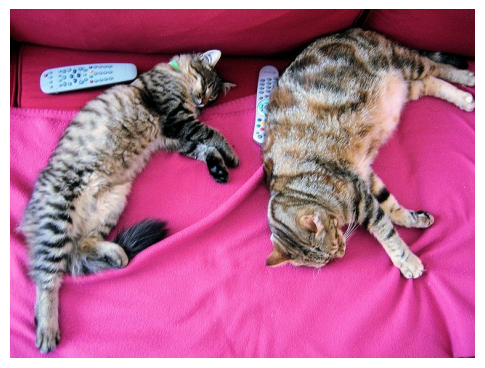

In [4]:
# The image is read from the local assets folder (prepare_assets.py puts two cats on a sofa there).
# To use your own photo, replace assets/image.jpg (keep it bicycle-free for Exercise 12).
IMAGE_PATH = os.path.join(ASSETS_DIR, "image.jpg")
assert os.path.exists(IMAGE_PATH), "assets/image.jpg not found -> run `python prepare_assets.py` first"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

In [5]:
arr = np.array(image)
w, h = image.size
print(f"Q5: size = {w} x {h} pixels (width x height); PIL .size is (W, H)")
print(f"Q6: mode = {image.mode}; as an array: shape {arr.shape} (H, W, channels), dtype {arr.dtype}, "
      f"values in [{arr.min()}, {arr.max()}]")

Q5: size = 640 x 480 pixels (width x height); PIL .size is (W, H)
Q6: mode = RGB; as an array: shape (480, 640, 3) (H, W, channels), dtype uint8, values in [0, 255]


### Answers — Exercise 2

**Q5.** Printed above. PIL reports `(width, height)`. The default COCO image is 640 × 480.

**Q6.** A PIL `Image` stores a raster of **8-bit unsigned integer pixels**. After `.convert("RGB")` there are 3 channels (R, G, B) with values 0–255. Converted with `np.array`, it becomes a `uint8` array of shape `(height, width, 3)`. The object also carries metadata: mode, size, format. `CLIPProcessor` later converts it to a float tensor of shape `[1, 3, 224, 224]`, normalized per channel.

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [6]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9829
a photo of a dog                   : 0.0050
a photo of a car                   : 0.0035
a photo of a horse                 : 0.0017
a photo of a person                : 0.0069


Q7: highest probability -> 'a photo of a cat'  (p = 0.9829)

Raw logits (100 x cosine similarity):
  a photo of a cat          logit =  24.04   cosine = 0.2404
  a photo of a dog          logit =  18.76   cosine = 0.1876
  a photo of a car          logit =  18.39   cosine = 0.1839
  a photo of a horse        logit =  17.69   cosine = 0.1769
  a photo of a person       logit =  19.09   cosine = 0.1909


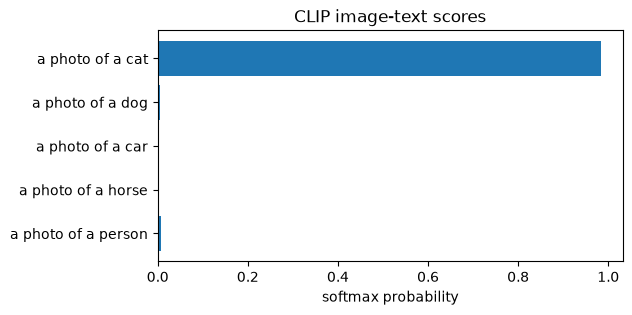

In [7]:
best = int(probs.argmax())
raw = outputs.logits_per_image[0].cpu()
print(f"Q7: highest probability -> '{texts[best]}'  (p = {probs[best]:.4f})")
print("\nRaw logits (100 x cosine similarity):")
for t, l in zip(texts, raw):
    print(f"  {t:25s} logit = {l:6.2f}   cosine = {l / logit_scale:.4f}")

plt.figure(figsize=(6, 3))
plt.barh(texts, probs.numpy()); plt.gca().invert_yaxis()
plt.xlabel("softmax probability"); plt.title("CLIP image-text scores"); plt.show()

### Answers — Exercise 3

**Q7.** *"a photo of a cat"*, with probability **0.983**. The other four captions share the remaining 1.7%: person 0.007, dog 0.005, car 0.004, horse 0.002.

**Q8.** Yes. The image shows two cats lying on a pink sofa, so the top caption is correct. The margin in raw similarity is small, though: cosine 0.240 for "cat" against 0.191 for the runner-up "person". The softmax temperature turns that gap of 0.05 into a 98% probability.

**Q9. Why can CLIP compare an image with a sentence?**
Both modalities are projected into the **same 512-d space**, and contrastive training has aligned that space: an image and a caption describing it get high cosine similarity. Once both are vectors in one space, "comparing" an image with a sentence is just a dot product of two normalized vectors. Neither encoder ever sees the other's raw input.

**Q10. What does `softmax()` do?**
It turns the 5 logits $z_i$ into a probability distribution, $p_i = e^{z_i} / \sum_j e^{z_j}$: all positive, summing to 1. These are **relative** scores, conditional on the candidate list: changing the list changes every probability. The logits are 100 × cosine, and that large temperature makes the distribution sharp. Here the cosines differ by only a few hundredths, yet the top caption gets ≈0.99. The raw cosine similarities are printed above for comparison.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

In [8]:
# STUDENT TASK — solution
def classify_image(image, classes, template="a photo of a {}.", return_all=False):
    # Zero-shot classification: the classifier weights are the text embeddings of one prompt per class.
    prompts = [template.format(c) for c in classes]
    img_emb = clip_image_embeddings([image])            # [1, 512]
    txt_emb = clip_text_embeddings(prompts)             # [C, 512]
    logits = logit_scale * img_emb @ txt_emb.T          # [1, C]
    p = logits.softmax(dim=-1)[0].cpu()
    idx = int(p.argmax())
    if return_all:
        return classes[idx], float(p[idx]), dict(zip(classes, p.numpy().round(4)))
    return classes[idx], float(p[idx])

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability, all_probs = classify_image(image, classes, return_all=True)
print("Prediction:", prediction)
print("Probability:", round(probability, 4))
print("All classes:", all_probs)

Prediction: cat
Probability: 0.989
All classes: {'cat': np.float32(0.989), 'dog': np.float32(0.0035), 'car': np.float32(0.0041), 'airplane': np.float32(0.0019), 'horse': np.float32(0.001), 'bird': np.float32(0.0006)}


In [9]:
# Q13 experiment: remove the true class from the candidates
classes_without_true = [c for c in classes if c != prediction]
pred2, p2, all2 = classify_image(image, classes_without_true, return_all=True)
print(f"Candidates without '{prediction}': {classes_without_true}")
print(f"-> CLIP still answers '{pred2}' with probability {p2:.3f}")
print("   all:", all2)
img_emb = clip_image_embeddings([image])
cos_true = (img_emb @ clip_text_embeddings([f"a photo of a {prediction}."]).T).item()
cos_forced = (img_emb @ clip_text_embeddings([f"a photo of a {pred2}."]).T).item()
print(f"   raw cosine: true class {cos_true:.3f} vs forced choice {cos_forced:.3f}  <- the absolute score drops")

Candidates without 'cat': ['dog', 'car', 'airplane', 'horse', 'bird']
-> CLIP still answers 'car' with probability 0.369
   all: {'dog': np.float32(0.3223), 'car': np.float32(0.369), 'airplane': np.float32(0.1689), 'horse': np.float32(0.0881), 'bird': np.float32(0.0516)}
   raw cosine: true class 0.242 vs forced choice 0.187  <- the absolute score drops


### Answers — Exercise 4

**Q11. What is zero-shot classification?**
Classifying an image into categories that the model was **never explicitly trained to recognize**, with zero labelled examples of them. With CLIP, each class name becomes a prompt ("a photo of a {class}."). The image is assigned to the prompt whose embedding is most similar to its own.

**Q12. Why is no new classifier needed?**
The text encoder builds the classifier on the fly: the C prompt embeddings act as the weight matrix of a linear classifier over image embeddings. The image–text alignment was already learned during pre-training on 400M pairs. So no labelled dataset, gradient step or fine-tuning is needed. Changing the classes only requires changing a list of strings.

**Q13. What if the correct class is not in the candidate list?**
CLIP performs a **closed-set** choice: the softmax must distribute all its mass over the given classes. It therefore returns the *least dissimilar* wrong class. In our run, after removing "cat", CLIP chose **"car" (p = 0.37)**, closely followed by "dog" (0.32). That is an absurd answer for a photo of two cats, given with a sizeable probability. The probability is relative to the list, so it is not a measure of correctness. One sign of the problem is the raw cosine similarity: 0.187 for the forced choice "car" against 0.242 for the true class "cat". Mitigations:
- add an "other / something else" class;
- put a threshold on the raw cosine similarity;
- make the label set cover the expected content.

## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [10]:
# STUDENT TASK — solution
# The labelled set is read from assets/eval/<class>/*.jpg : the sub-folder name is the label.
# prepare_assets.py fills it with 5 CIFAR-10 test images per class; add or replace with your own photos.
dataset = [
    (path, label)
    for label in sorted(os.listdir(EVAL_DIR)) if os.path.isdir(os.path.join(EVAL_DIR, label))
    for path in list_images(os.path.join(EVAL_DIR, label))
]
# (equivalent to the format of the statement: [("assets/eval/cat/cat1.png", "cat"), ...])

unknown = sorted({l for _, l in dataset} - set(classes))
if unknown:
    print("Note: these folder labels are not in `classes`, so they can never be predicted:", unknown)
assert len(dataset) >= 10, "Need at least 10 labelled images in assets/eval/<class>/"
print(len(dataset), "labelled images:", pd.Series([l for _, l in dataset]).value_counts().to_dict())

# Evaluation
rows = []
for path, label in dataset:
    pred, p = classify_image(Image.open(path).convert("RGB"), classes)
    rows.append({"image": os.path.basename(path), "actual": label, "predicted": pred,
                 "probability": round(p, 4), "correct": pred == label})
results_df = pd.DataFrame(rows)
clip_accuracy = results_df["correct"].mean()
display(results_df)
results_df.to_csv(os.path.join(RESULTS_DIR, "clip_classification.csv"), index=False)
print(f"Q14: Accuracy = {results_df['correct'].sum()}/{len(results_df)} = {clip_accuracy:.2%}")

30 labelled images: {'airplane': 5, 'bird': 5, 'car': 5, 'cat': 5, 'dog': 5, 'horse': 5}


,image,actual,predicted,probability,correct
0,airplane1.png,airplane,airplane,0.9703,True
1,airplane2.png,airplane,airplane,0.9728,True
2,airplane3.png,airplane,airplane,0.9766,True
3,airplane4.png,airplane,airplane,0.9853,True
4,airplane5.png,airplane,airplane,0.9860,True
5,bird1.png,bird,horse,0.8364,False
6,bird2.png,bird,dog,0.7349,False
7,bird3.png,bird,bird,0.9620,True
8,bird4.png,bird,bird,0.9987,True
9,bird5.png,bird,bird,0.9960,True


Q14: Accuracy = 27/30 = 90.00%


Q15: 3 misclassified image(s)


,image,actual,predicted,probability,correct
5,bird1.png,bird,horse,0.8364,False
6,bird2.png,bird,dog,0.7349,False
15,cat1.png,cat,dog,0.6334,False


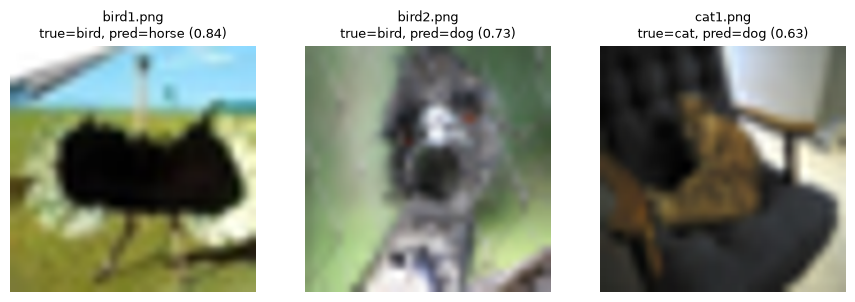

Per-class accuracy:


,accuracy
actual,
airplane,1.0
bird,0.6
car,1.0
cat,0.8
dog,1.0
horse,1.0


Confusion matrix (rows = actual, columns = predicted):


predicted,airplane,bird,car,cat,dog,horse
actual,,,,,,
airplane,5,0,0,0,0,0
bird,0,3,0,0,1,1
car,0,0,5,0,0,0
cat,0,0,0,4,1,0
dog,0,0,0,0,5,0
horse,0,0,0,0,0,5


In [11]:
errors = results_df[~results_df["correct"]]
print(f"Q15: {len(errors)} misclassified image(s)")
display(errors)
if len(errors):
    paths = {os.path.basename(p): p for p, _ in dataset}
    show_grid([paths[r.image] for r in errors.itertuples()],
              [f"{r.image}\ntrue={r.actual}, pred={r.predicted} ({r.probability:.2f})" for r in errors.itertuples()],
              ncols=min(5, len(errors)), save_path=os.path.join(RESULTS_DIR, "clip_misclassified.png"))

print("Per-class accuracy:")
display(results_df.groupby("actual")["correct"].mean().round(2).to_frame("accuracy"))
print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.crosstab(results_df["actual"], results_df["predicted"]))

### Answers — Exercise 5

**Q14.** Accuracy = 27 / 30 = **90.0%**. Airplane, car, dog and horse are all 5/5, cat is 4/5 and bird 3/5. This matches the ≈89% zero-shot accuracy reported for ViT-B/32 on the full CIFAR-10 test set. With only 30 images, each error is worth 3.3 points, so the number is a rough estimate.

**Q15.** Three images are misclassified:

| Image | True | Predicted | p |
|---|---|---|---|
| `bird1.png` | bird | horse | 0.84 |
| `bird2.png` | bird | dog | 0.73 |
| `cat1.png` | cat | dog | 0.63 |

**Q16. Reasons for the errors.** The error grid shows that the two "birds" are ostrich/emu-like animals: a dark, long-legged body on grass, and a close-up of a head. `cat1` is a dark cat on a black armchair.
1. **Atypical class members.** Ostriches and emus are birds, but they look nothing like the small flying birds that dominate the image–text pairs for "bird". A large dark animal standing on grass looks more like a horse to CLIP.
2. **Low resolution.** CIFAR images are 32×32 pixels upscaled to 224×224. The ostrich head is a blur of fur-like texture, which pushes it towards "dog". CLIP was trained on sharp web photos, so these thumbnails are out of distribution.
3. **Visually similar classes and poor contrast.** cat vs dog is the classic confusion. In `cat1`, the cat blends into a dark armchair, so the low-confidence prediction (0.63) reflects real ambiguity.

The errors are also among the least confident predictions (0.63–0.84), while 25 of the 27 correct ones are above 0.92. Two correct predictions are also unsure (car5 at 0.73, dog2 at 0.85), so a confidence threshold would flag the risky cases but not separate them perfectly.

General causes, for reference:
1. **Low resolution / domain shift.** CIFAR images are 32×32, upscaled to 224×224. CLIP was trained mostly on sharp web photos, so blurry thumbnails are out of distribution.
2. **Visually similar classes.** cat↔dog, bird↔airplane (sky backgrounds), horse↔dog: classes that share shape, texture or context get confused.
3. **Background and context bias.** CLIP sometimes classifies the scene rather than the object, e.g. sky → airplane/bird, road → car.
4. **Prompt wording.** A single template such as "a photo of a {}." is not optimal for every class or image style (see Exercise 6). For blurry images, "a blurry photo of a {}." often helps.
5. **Ambiguous images.** Small objects, partial views, unusual poses, several objects in one image.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [12]:
# STUDENT TASK — solution (uses the cat image from Exercise 2)
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

img_emb = clip_image_embeddings([image])
txt_emb = clip_text_embeddings(prompts)
cos = (img_emb @ txt_emb.T)[0].cpu()
prompt_df = pd.DataFrame({
    "prompt": prompts,
    "cosine similarity": cos.numpy().round(4),
    "CLIP score (100 x cos)": (logit_scale * cos).numpy().round(2),
}).sort_values("cosine similarity", ascending=False).reset_index(drop=True)
display(prompt_df)

top = prompt_df.iloc[0]
print(f"Q17: identical? {prompt_df['cosine similarity'].nunique() == 1}  "
      f"(range {prompt_df['cosine similarity'].min():.4f} - {prompt_df['cosine similarity'].max():.4f})")
print(f"Q18: best prompt -> '{top['prompt']}'  (cos = {top['cosine similarity']:.4f})")
# We compare raw cosine scores: a softmax across these 5 prompts would be meaningless,
# because all of them describe the correct class.

,prompt,cosine similarity,CLIP score (100 x cos)
0,a photograph showing a cat,0.2511,25.110001
1,an image containing a cat,0.2490,24.900000
2,a photo of a cat,0.2404,24.040001
3,a domestic animal called a cat,0.2366,23.660000
4,a cat,0.2269,22.690001


Q17: identical? False  (range 0.2269 - 0.2511)
Q18: best prompt -> 'a photograph showing a cat'  (cos = 0.2511)


In [13]:
# Going further: does prompt wording change *accuracy*? Test templates on the Exercise 5 set,
# plus prompt ensembling (average the text embeddings of several templates per class).
templates = ["{}", "a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.",
             "an image containing a {}."]
eval_imgs = [Image.open(p).convert("RGB") for p, _ in dataset]
eval_labels = [l for _, l in dataset]
eval_emb = clip_image_embeddings(eval_imgs)

def class_weights(tpls):
    w = torch.stack([clip_text_embeddings([t.format(c) for t in tpls]).mean(0) for c in classes])
    return F.normalize(w, dim=-1)

def accuracy_with(weights):
    pred = (eval_emb @ weights.T).argmax(1).cpu().numpy()
    return np.mean([classes[i] == y for i, y in zip(pred, eval_labels)])

acc_rows = [{"template(s)": t, "accuracy": accuracy_with(class_weights([t]))} for t in templates]
acc_rows.append({"template(s)": "ensemble of all 5", "accuracy": accuracy_with(class_weights(templates))})
display(pd.DataFrame(acc_rows).round(3))

,template(s),accuracy
0,{},0.9
1,a photo of a {}.,0.9
2,a blurry photo of a {}.,0.9
3,a low resolution photo of a {}.,0.9
4,an image containing a {}.,0.9
5,ensemble of all 5,0.9


### Answers — Exercise 6

**Q17.** No. The cosine similarities range from **0.2269** ("a cat") to **0.2511** ("a photograph showing a cat"). The prompts all mean "cat", but each produces a different text embedding. The spread of 0.024 is 2.4 logit points after CLIP's ×100 temperature, enough to change a softmax decision between close classes.

**Q18.** *"a photograph showing a cat"* (cos 0.2511), then "an image containing a cat" (0.2490) and "a photo of a cat" (0.2404). The bare word "a cat" scores lowest. Full caption-like sentences look more like the web captions CLIP was trained on.

**Q19. What does this show?**
CLIP's text encoder is **sensitive to the wording**, not only to the class name. The prompt is effectively part of the classifier. In practice:
- prompts that match the style of the training captions work better ("a photo of a {}.");
- adding context about the image domain helps ("a blurry photo of …", "a satellite photo of …");
- averaging several prompts (**prompt ensembling**) is more robust than any single prompt. The CLIP paper reports gains of a few points on ImageNet from prompt engineering plus ensembling.

On our 30-image evaluation set, the template study gave the **same accuracy (90%) for every template and for the ensemble**. The three errors are hard images (ostriches, a dark cat) that no wording rescues. 30 images is also too few to resolve differences of 1–2 points, whereas the CLIP paper measures them on tens of thousands of images. So the wording changes the scores, as Q17 shows, but on easy classes it rarely changes the decision. Prompt formulation is still a hyper-parameter to choose and report, much like a learning rate.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

Database: 21 images, embeddings (21, 512), norms ~ 1.000  (saved to clip_image_db.pt)


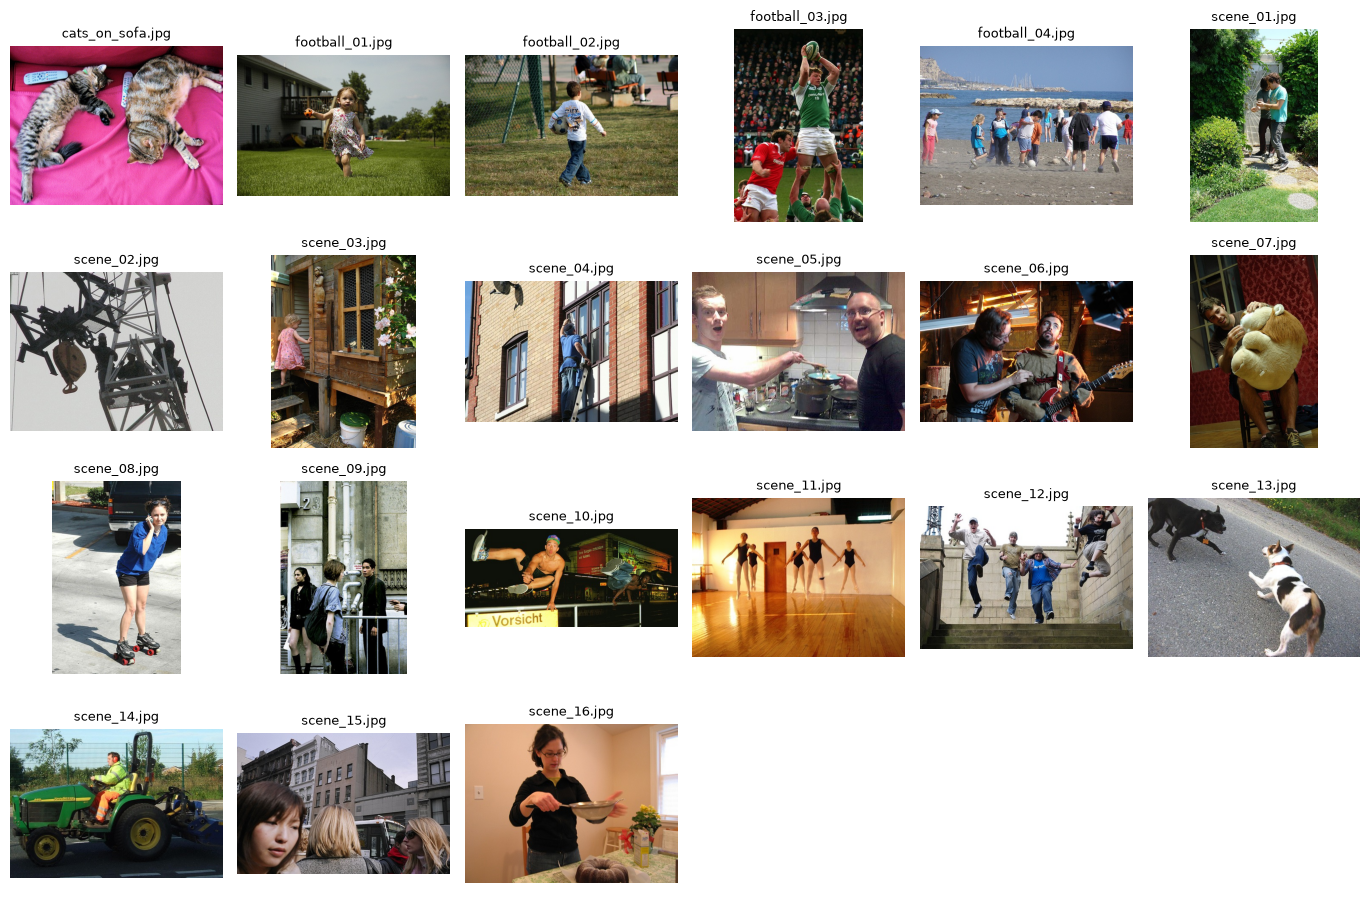

In [14]:
# STUDENT TASK — solution, step 1: build the image database (>= 20 images)
IMAGE_DIR = DB_DIR            # assets/database
QUERY = "a person playing football"

db_paths = list_images(IMAGE_DIR)
if len(db_paths) < 20:
    print(f"WARNING: only {len(db_paths)} image(s) in {IMAGE_DIR}/ - the lab asks for at least 20.")
if not any(k in os.path.basename(p).lower() for p in db_paths for k in ("football", "soccer", "sport")):
    print("Tip: make sure the database contains a few football photos, otherwise the query has no true match.")
assert db_paths, f"No images in {IMAGE_DIR}/ -> run `python prepare_assets.py` or add your own photos"

db_images = [Image.open(p).convert("RGB") for p in db_paths]
db_emb = clip_image_embeddings(db_images)            # normalized, [N, 512]
torch.save({"paths": db_paths, "embeddings": db_emb.cpu()}, "clip_image_db.pt")
print(f"Database: {len(db_paths)} images, embeddings {tuple(db_emb.shape)}, "
      f"norms ~ {db_emb.norm(dim=1).mean():.3f}  (saved to clip_image_db.pt)")
show_grid(db_images, [os.path.basename(p)[:22] for p in db_paths], ncols=6, size=2.3)

,rank,image,cosine
0,1,football_02.jpg,0.2956
1,2,football_03.jpg,0.2655
2,3,football_01.jpg,0.2468
3,4,football_04.jpg,0.2410
4,5,scene_10.jpg,0.2345


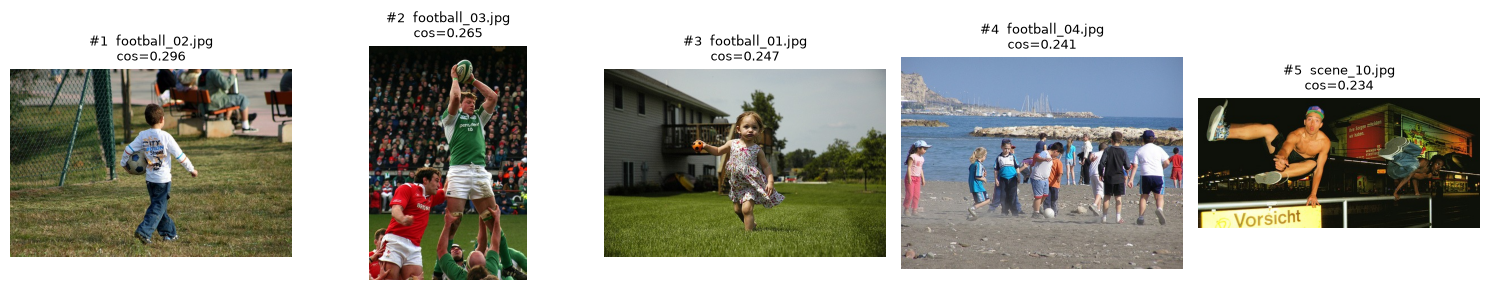

Q20: most similar image -> football_02.jpg (cosine 0.296)


In [15]:
# Steps 2-5: text-to-image retrieval
def search(query, k=5):
    q = clip_text_embeddings([query])                 # [1, 512], normalized
    sims = (db_emb @ q.T).squeeze(1).cpu()            # cosine similarity = dot product of unit vectors
    top = sims.topk(min(k, len(sims)))
    return top.indices.tolist(), top.values.tolist()

top_idx, top_scores = search(QUERY, k=5)
retrieval_df = pd.DataFrame({"rank": range(1, len(top_idx) + 1),
                             "image": [os.path.basename(db_paths[i]) for i in top_idx],
                             "cosine": np.round(top_scores, 4)})
display(retrieval_df)
show_grid([db_images[i] for i in top_idx],
          [f"#{r + 1}  {os.path.basename(db_paths[i])[:20]}\ncos={s:.3f}" for r, (i, s) in enumerate(zip(top_idx, top_scores))],
          save_path=os.path.join(RESULTS_DIR, "retrieval_top5.png"))
retrieval_df.to_csv(os.path.join(RESULTS_DIR, "retrieval_top5.csv"), index=False)
print(f"Q20: most similar image -> {os.path.basename(db_paths[top_idx[0]])} (cosine {top_scores[0]:.3f})")

In [16]:
# Extra queries, to see that the same database answers any free-text query without re-indexing
for q in ["two cats sleeping on a sofa", "a dog", "people eating at a restaurant", "a red car"]:
    idx, sc = search(q, k=3)
    print(f"{q!r:35s} -> " + ", ".join(f"{os.path.basename(db_paths[i])} ({s:.3f})" for i, s in zip(idx, sc)))

'two cats sleeping on a sofa'       -> cats_on_sofa.jpg (0.299), scene_07.jpg (0.178), scene_01.jpg (0.154)
'a dog'                             -> scene_13.jpg (0.239), scene_07.jpg (0.227), scene_01.jpg (0.216)
'people eating at a restaurant'     -> scene_15.jpg (0.211), scene_09.jpg (0.206), scene_16.jpg (0.201)
'a red car'                         -> scene_14.jpg (0.216), scene_08.jpg (0.197), scene_15.jpg (0.190)


### Answers — Exercises 7 & 8

**Q20.** `football_02.jpg` (cosine 0.296), a young boy playing with a soccer ball in a field.

**Q21.** Yes. The **four football photos in the database occupy ranks 1–4** (cosines 0.296, 0.266, 0.247, 0.241), and every relevant image is retrieved before any irrelevant one: precision@4 = 1.0. Rank 5 (`scene_10.jpg`, 0.235) is the most similar non-football scene. The gap between rank 4 and rank 5 is small (0.006), because cosine similarities in CLIP's space are compressed into a narrow band, roughly 0.15–0.30. The extra queries confirm the behaviour: "two cats sleeping on a sofa" retrieves `cats_on_sofa.jpg` first with a clear margin (0.299 against 0.178).

**Q22. Why are no labels needed?**
Every image is indexed by its CLIP embedding, computed from the pixels alone. The query is embedded by the text encoder into the *same* space. Ranking is just cosine similarity between the two, so labels, tags and captions are never used. The image–text knowledge was learned once, during CLIP pre-training. Any new free-text query works on the same index without retraining, as the extra queries above show.

**Q23. One real-world application.**
For example:
- natural-language search in a personal photo library ("my dog on the beach"), as in modern phone gallery apps;
- e-commerce product search from a description;
- searching archives of news photos or medical images;
- curating large datasets by finding images that match a concept, as done for the LAION datasets;
- content moderation.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

### Answers — Exercise 9

```text
Image
  |
  v
CLIP Vision Encoder        (ViT-L/14 @ 336 px, frozen -> 24x24 = 576 patch features, 1024-d)
  |
  v
Projection layer           (LLaVA-1: linear layer; LLaVA-1.5: 2-layer MLP with GELU -> 4096-d "visual tokens")
  |
  v
Language Model             (Vicuna-7B/13B, reads [visual tokens + text prompt tokens])
  |
  v
Text Response              (generated token by token)
```

**Q24. Role of the vision encoder.**
It turns the raw pixels into a **sequence of semantic feature vectors**, one per image patch. In LLaVA-1.5 this is the pre-trained CLIP ViT-L/14-336, and the features come from its penultimate layer. Because CLIP was trained to align images with language, these features already encode concepts that are easy to connect to words. The encoder is kept frozen during training.

**Q25. Why is a projection layer required?**
The vision features and the LLM's word embeddings live in **different spaces with different dimensions** (1024 vs 4096 for Vicuna-7B). The LLM was never trained to understand CLIP features. The projector is a trainable linear map (LLaVA-1) or a small MLP (LLaVA-1.5). It translates each patch feature into a vector in the LLM's token-embedding space, a **"visual token"** that the LLM can read just like a word. This is the main component learned in LLaVA's stage-1 training (feature alignment on image–caption pairs, with the encoder and LLM frozen).

**Q26. Role of the language model.**
The LLM (Vicuna, a LLaMA fine-tune) receives the sequence `[visual tokens] + [user question]` and **generates the answer autoregressively**. It supplies the language understanding, world knowledge, reasoning and instruction-following. In stage 2 (visual instruction tuning on GPT-generated multimodal conversations), the projector and the LLM are fine-tuned together so that the LLM learns to ground its answers in the visual tokens.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [17]:
# LLaVA - solution, for a local 16 GB GPU (RTX 5070 Ti).
# LLaVA-1.5-7B has ~7B parameters: fp16 needs ~14 GB just for the weights, which together with CLIP
# leaves almost no room on 16 GB. So by default it is loaded in 4-bit NF4 (~5 GB of VRAM).
# If bitsandbytes does not work on your setup, it falls back to fp16 with automatic CPU offload
# (works, but slower). Without any GPU, a small 0.5B LLaVA-architecture model is used instead.
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

LLAVA_PRECISION = "4bit"          # "4bit" (default), "8bit" or "fp16"

def load_llava(model_id, precision):
    if precision in ("4bit", "8bit"):
        quant = (BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                    bnb_4bit_compute_dtype=torch.float16)
                 if precision == "4bit" else BitsAndBytesConfig(load_in_8bit=True))
        m = LlavaForConditionalGeneration.from_pretrained(model_id, quantization_config=quant,
                                                          torch_dtype=torch.float16, device_map="cuda:0",
                                                          low_cpu_mem_usage=True)
    else:
        m = LlavaForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16,
                                                          device_map="auto", low_cpu_mem_usage=True)
    return m

if torch.cuda.is_available():
    MODEL_ID = "llava-hf/llava-1.5-7b-hf"
    llava_dtype = torch.float16
    try:
        llava = load_llava(MODEL_ID, LLAVA_PRECISION)
    except Exception as e:
        print(f"{LLAVA_PRECISION} loading failed ({type(e).__name__}: {str(e)[:150]})")
        print("-> falling back to fp16 with automatic CPU offload")
        torch.cuda.empty_cache()
        LLAVA_PRECISION = "fp16"
        llava = load_llava(MODEL_ID, "fp16")
else:
    MODEL_ID = "llava-hf/llava-interleave-qwen-0.5b-hf"
    llava_dtype = torch.float32
    LLAVA_PRECISION = "fp32 (CPU)"
    llava = LlavaForConditionalGeneration.from_pretrained(MODEL_ID, torch_dtype=torch.float32, low_cpu_mem_usage=True)
    print("No GPU found: using the small 0.5B LLaVA model.")

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava.eval()
print(f"Loaded {MODEL_ID} ({LLAVA_PRECISION}) on {llava.device}")
if torch.cuda.is_available():
    print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB "
          f"of {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Loaded llava-hf/llava-1.5-7b-hf (4bit) on cuda:0
GPU memory in use: 5.0 GB of 17.1 GB


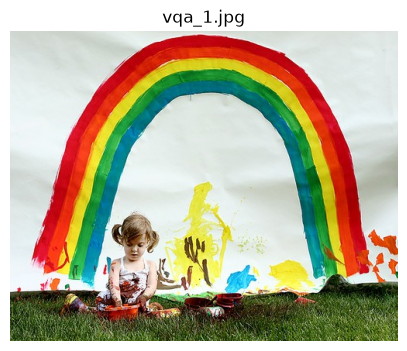

Q: What is happening in this image?
A: In the image, a little girl is sitting on the grass in front of a colorful rainbow painting. She is
surrounded by various art supplies, including a bowl and a cup, which are likely used for painting
and other creative activities. The scene suggests that the little girl is engaged in a fun and
creative activity, possibly painting or drawing on the rainbow painting.

Q: How many people are visible?
A: There is only one person visible in the image, a little girl.

Q: What objects can you identify?
A: In the image, you can identify a little girl sitting on the grass, a rainbow-colored backdrop, and a
bowl of paint. The little girl is painting on the grass, and the bowl of paint is placed nearby. The
scene suggests a fun and creative outdoor activity for the child.

Q: Describe the image in detail.
A: The image features a young child sitting on the grass in front of a large, colorful rainbow
painting. The child appears to be enjoying the painting and i

In [18]:
@torch.no_grad()
def ask_llava(image, question, history=None, max_new_tokens=200):
    # history: list of (question, answer) pairs from earlier turns about the same image
    history = history or []
    conversation = []
    for i, (q, a) in enumerate(history):
        content = ([{"type": "image"}] if i == 0 else []) + [{"type": "text", "text": q}]
        conversation.append({"role": "user", "content": content})
        conversation.append({"role": "assistant", "content": [{"type": "text", "text": a}]})
    content = ([{"type": "image"}] if not history else []) + [{"type": "text", "text": question}]
    conversation.append({"role": "user", "content": content})
    try:
        prompt = processor_llava.apply_chat_template(conversation, add_generation_prompt=True)
    except Exception:   # older transformers: LLaVA-1.5 prompt format written by hand
        turns = "".join(f"USER: {'<image>' + chr(10) if i == 0 else ''}{q} ASSISTANT: {a}</s>"
                        for i, (q, a) in enumerate(history))
        prompt = turns + f"USER: {'<image>' + chr(10) if not history else ''}{question} ASSISTANT:"
    inputs = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, llava_dtype)
    out = llava.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)   # greedy = reproducible
    return processor_llava.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def show_qa(image, qa_pairs, title=None):
    plt.figure(figsize=(5, 5)); plt.imshow(image); plt.axis("off")
    if title: plt.title(title)
    plt.show()
    for q, a in qa_pairs:
        print(f"Q: {q}\nA: {wrap(a)}\n")

# Exercise 10: the first image of assets/vqa (a scene with people), otherwise the main image
vqa_folder_paths = list_images(VQA_DIR)
ex10_path = vqa_folder_paths[0] if vqa_folder_paths else IMAGE_PATH
ex10_image = Image.open(ex10_path).convert("RGB")
ex10_questions = ["What is happening in this image?", "How many people are visible?",
                  "What objects can you identify?", "Describe the image in detail."]
ex10_answers = [(q, ask_llava(ex10_image, q)) for q in ex10_questions]
show_qa(ex10_image, ex10_answers, title=os.path.basename(ex10_path))

**Recorded answers (Ex. 10, `vqa_1.jpg`: a little girl sitting on the grass in front of a large painted rainbow, with paint bowls around her).**

| Question | LLaVA's answer (summary) | Correct? |
|---|---|---|
| What is happening? | A little girl sitting on the grass in front of a rainbow painting, with art supplies, engaged in painting | ✅ |
| How many people? | One, a little girl | ✅ |
| What objects? | The girl, a rainbow backdrop, a bowl of paint | ✅ |
| Describe in detail | Child on grass in front of a large rainbow painting, several bowls of paint, two cups, a spoon | ✅ mostly. The bowls are right; the "two cups" and the "spoon" cannot be confirmed and are probably invented details |

The global scene, the count and the main objects are right. The long description is where invented fine details start to appear.

## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

VQA images: ['vqa\\vqa_1.jpg', 'vqa\\vqa_2.jpg', 'vqa\\vqa_3.jpg', 'vqa\\vqa_4.jpg', 'vqa\\vqa_5.jpg']


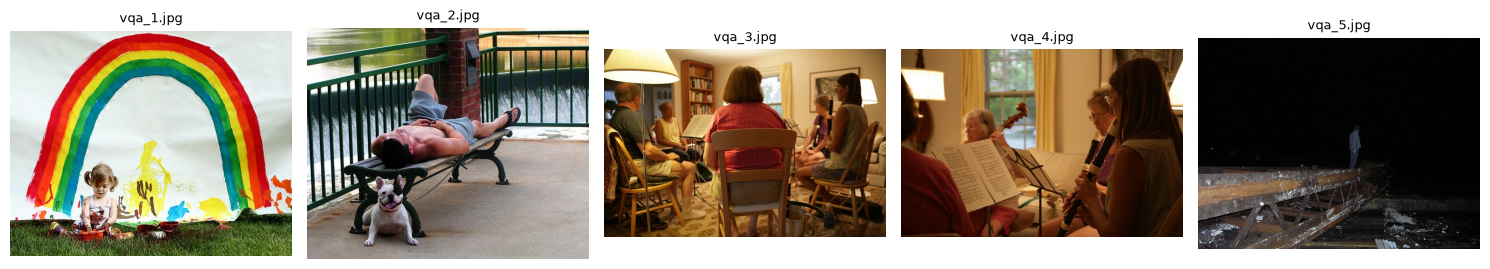

,Image,Question,LLaVA Answer,Human Evaluation
0,vqa_1.jpg,How many people are visible?,"There is only one person visible in the image, a little girl.",None
1,vqa_1.jpg,What objects can you see?,"In the image, you can see a little girl, a rainbow, and a painting area. The girl is sitting in front of the rainbow, and there are several bowls and cups on the ground near her.",None
2,vqa_1.jpg,Where are the people?,"The people are in the background, behind the child who is painting on the wall.",None
3,vqa_1.jpg,What are they doing?,The little girl is painting a picture of a rainbow on a large piece of paper.,None
4,vqa_1.jpg,"Is there any text visible (for example on a board or a sign)? If so, what does it say?","Yes, there is text visible in the image. The text says ""Rainbow.""",None
5,vqa_2.jpg,How many people are visible?,There is only one person visible in the image.,None
6,vqa_2.jpg,What objects can you see?,"In the image, you can see a man lying on a bench, a dog sitting on a bench next to him, and a waterfall in the background.",None
7,vqa_2.jpg,Where are the people?,The people are not visible in the image. The focus is on the dog and the bench where the dog is sitting.,None
8,vqa_2.jpg,What are they doing?,"The man is laying on a bench, possibly taking a nap or resting, while the dog is sitting or laying nearby.",None
9,vqa_2.jpg,"Is there any text visible (for example on a board or a sign)? If so, what does it say?","Yes, there is a sign visible in the image. The sign says ""no swimming.""",None


In [19]:
# 5 images x 5 questions = 25 answers. Images come from assets/vqa (topped up from the database if needed).
vqa_paths = list(dict.fromkeys(vqa_folder_paths + [IMAGE_PATH] + db_paths))[:5]
print("VQA images:", [os.path.relpath(p, ASSETS_DIR) for p in vqa_paths])
vqa_questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where are the people?",
    "What are they doing?",
    "Is there any text visible (for example on a board or a sign)? If so, what does it say?",
]
vqa_rows = []
for path in vqa_paths:
    img = Image.open(path).convert("RGB")
    for q in vqa_questions:
        vqa_rows.append({"Image": os.path.basename(path), "Question": q,
                         "LLaVA Answer": ask_llava(img, q, max_new_tokens=80), "Human Evaluation": None})
vqa_df = pd.DataFrame(vqa_rows)
vqa_df.to_csv(os.path.join(RESULTS_DIR, "vqa_results.csv"), index=False)

show_grid(vqa_paths, [os.path.basename(p) for p in vqa_paths], ncols=5)
pd.set_option("display.max_colwidth", 200)
display(vqa_df)

In [20]:
# HUMAN EVALUATION (done by looking at each image): 1 = correct, 0 = wrong, in table order.
# Rule: an answer is correct if its main claim answers the question correctly and it does not invent
# an object or text that is not in the image. A wrong secondary detail alone does not fail an answer.
human_eval = [
    # vqa_1: girl painting in front of a rainbow
    1,  # count: one girl                                                   - correct
    1,  # objects: girl, rainbow, bowls, cups                               - correct
    0,  # where: "people in the background" - there is nobody else          - wrong
    1,  # doing: painting                                                   - correct
    0,  # text: "Rainbow" - no text in the image                            - wrong (invented text)
    # vqa_2: man lying on a bench, French bulldog on the ground, waterfall behind
    1,  # count: one                                                        - correct
    1,  # objects: man, bench, dog, waterfall (dog placed "on the bench")   - correct, minor detail wrong
    0,  # where: "the people are not visible" - the man is clearly visible  - wrong
    1,  # doing: man resting on the bench, dog nearby                       - correct
    0,  # text: "no swimming" - no sign in the image                        - wrong (invented text)
    # vqa_3: five people playing recorders in a living room
    1,  # count: five                                                       - correct
    1,  # objects: chairs, bookshelf, lamp, books                           - correct
    1,  # where: living room, on chairs, playing instruments                - correct
    1,  # doing: playing music together ("around a table" is wrong)         - correct
    0,  # text: "no smoking" - no sign in the image                         - wrong (invented text)
    # vqa_4: four musicians (recorders, a cello), sheet music on a stand
    1,  # count: four                                                       - correct
    0,  # objects: "violin", "instruments placed on a table" - not in image - wrong (invented objects)
    1,  # where: living room                                                - correct
    1,  # doing: playing musical instruments                                - correct
    1,  # text: "a music score on a stand" - yes, sheet music is visible    - correct
    # vqa_5: one person standing on a metal girder structure at night
    1,  # count: one                                                        - correct
    0,  # objects: "a boat" - there is no boat                              - wrong (invented object)
    0,  # where: "on a boat in the middle of the ocean"                     - wrong
    0,  # doing: "standing on a boat in the middle of the ocean"            - wrong
    0,  # text: "No Swimming" - no sign in the image                        - wrong (invented text)
]
assert len(human_eval) == len(vqa_df), f"{len(human_eval)} values for {len(vqa_df)} answers"

if all(v in (0, 1) for v in human_eval):
    vqa_df["Human Evaluation"] = ["correct" if v else "wrong" for v in human_eval]
    vqa_df["score"] = human_eval
    vqa_accuracy = vqa_df["score"].mean()
    vqa_df.to_csv(os.path.join(RESULTS_DIR, "vqa_results.csv"), index=False)
    display(vqa_df[["Image", "Question", "LLaVA Answer", "Human Evaluation"]])
    print(f"Q27: VQA accuracy = {sum(human_eval)}/{len(human_eval)} = {vqa_accuracy:.0%}")
    print("Accuracy by question type:")
    display(vqa_df.groupby("Question", sort=False)["score"].mean().round(2).to_frame("accuracy"))
else:
    vqa_accuracy = None
    print("Fill `human_eval` with 0/1 values (one per row of the table) and re-run this cell.")

,Image,Question,LLaVA Answer,Human Evaluation
0,vqa_1.jpg,How many people are visible?,"There is only one person visible in the image, a little girl.",correct
1,vqa_1.jpg,What objects can you see?,"In the image, you can see a little girl, a rainbow, and a painting area. The girl is sitting in front of the rainbow, and there are several bowls and cups on the ground near her.",correct
2,vqa_1.jpg,Where are the people?,"The people are in the background, behind the child who is painting on the wall.",wrong
3,vqa_1.jpg,What are they doing?,The little girl is painting a picture of a rainbow on a large piece of paper.,correct
4,vqa_1.jpg,"Is there any text visible (for example on a board or a sign)? If so, what does it say?","Yes, there is text visible in the image. The text says ""Rainbow.""",wrong
5,vqa_2.jpg,How many people are visible?,There is only one person visible in the image.,correct
6,vqa_2.jpg,What objects can you see?,"In the image, you can see a man lying on a bench, a dog sitting on a bench next to him, and a waterfall in the background.",correct
7,vqa_2.jpg,Where are the people?,The people are not visible in the image. The focus is on the dog and the bench where the dog is sitting.,wrong
8,vqa_2.jpg,What are they doing?,"The man is laying on a bench, possibly taking a nap or resting, while the dog is sitting or laying nearby.",correct
9,vqa_2.jpg,"Is there any text visible (for example on a board or a sign)? If so, what does it say?","Yes, there is a sign visible in the image. The sign says ""no swimming.""",wrong


Q27: VQA accuracy = 15/25 = 60%
Accuracy by question type:


,accuracy
Question,
How many people are visible?,1.0
What objects can you see?,0.6
Where are the people?,0.4
What are they doing?,0.8
"Is there any text visible (for example on a board or a sign)? If so, what does it say?",0.2


### Answers — Exercise 11

**Q27.** VQA accuracy = **15 / 25 = 60%**, graded by hand with the rule stated in the cell above. Per question type:

| Question type | Accuracy |
|---|---|
| How many people are visible? | **5/5 (100%)** |
| What are they doing? | 4/5 (80%) |
| What objects can you see? | 3/5 (60%) |
| Where are the people? | 2/5 (40%) |
| Is there any text visible? | **1/5 (20%)** |

**Q28. Which questions are difficult for LLaVA?**
- **Reading text (OCR) was by far the worst, and it is mainly hallucination, not misreading.** None of the five images contains a sign. LLaVA still "read" a sign in four of them: "Rainbow", "no swimming" (twice) and "no smoking". The question asked whether there was text, and the model answered as if there had to be. The only correct answer (vqa_4) identified real sheet music on a stand.
- **Location and presupposition questions ("Where are the people?").** The model said there were people "in the background" when there were none (vqa_1). On vqa_2 it said "the people are not visible", although it counted one man when asked how many people there were; the plural "people" in the question seems to have confused it. On vqa_5 it placed the person "on a boat in the middle of the ocean".
- **Dark or unusual scenes.** vqa_5 (a night shot of a man on a metal girder) produced a coherent but wrong story, a boat at sea, which then contaminated three of its five answers.
- **Fine-grained object identity.** In vqa_4, recorders became a "flute" and a "violin" appeared that is not there.

What worked: **counting was perfect here** (1, 1, 5, 4, 1 people). The scenes contain at most 5 clearly separated people; counting is known to degrade for larger or occluded crowds, which these images do not test. The main activity was also right in 4 of 5 images.

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

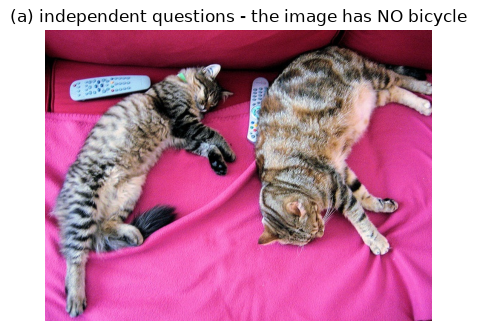

Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image features two cats sleeping on a couch.

Q: What color is the bicycle?
A: The bicycle is pink.

Q: Where is the bicycle located?
A: The bicycle is located in the living room.

(b) multi-turn conversation
Q: Is there a bicycle in this image?
A: No, there is no bicycle in this image. The image features two cats sleeping on a couch.

Q: What color is the bicycle?
A: The bicycle is blue.

Q: Where is the bicycle located?
A: The bicycle is located on the floor.

(c) with an explicit 'absent' option
Q: Look carefully. If there is a bicycle, what color is it? If there is no bicycle, answer 'There is no bicycle'.
A: There is no bicycle.

CLIP check: {'cat': np.float32(0.6899), 'dog': np.float32(0.0025), 'bicycle': np.float32(0.0012), 'sofa': np.float32(0.3064)}


In [21]:
# The default image (two cats on a sofa) contains no bicycle.
halluc_image = Image.open(IMAGE_PATH).convert("RGB")
bike_questions = ["Is there a bicycle in this image?",
                  "What color is the bicycle?",
                  "Where is the bicycle located?"]

# (a) Each question asked independently, in a fresh conversation
independent = [(q, ask_llava(halluc_image, q, max_new_tokens=60)) for q in bike_questions]
show_qa(halluc_image, independent, title="(a) independent questions - the image has NO bicycle")

# (b) The same questions as one conversation (the model sees its own earlier answers)
history = []
for q in bike_questions:
    history.append((q, ask_llava(halluc_image, q, history=history, max_new_tokens=60)))
print("(b) multi-turn conversation")
for q, a in history:
    print(f"Q: {q}\nA: {wrap(a)}\n")

# (c) A simple mitigation: explicitly allow the model to say the object is absent
safe_q = "Look carefully. If there is a bicycle, what color is it? If there is no bicycle, answer 'There is no bicycle'."
print("(c) with an explicit 'absent' option")
safe_answer = ask_llava(halluc_image, safe_q, max_new_tokens=60)
print(f"Q: {safe_q}\nA: {wrap(safe_answer)}")

# CLIP cross-check: is 'bicycle' plausible for this image at all?
clip_check = classify_image(halluc_image, ["cat", "dog", "bicycle", "sofa"], return_all=True)[2]
print("\nCLIP check:", clip_check)

# Save the hallucination example for the repository
with open(os.path.join(RESULTS_DIR, "hallucination_example.md"), "w", encoding="utf-8") as f:
    f.write(f"# Hallucination example ({MODEL_ID})\n\nImage: `{IMAGE_PATH}` (contains **no** bicycle)\n\n")
    for title, qa in [("Independent questions", independent), ("Multi-turn conversation", history)]:
        f.write(f"## {title}\n\n" + "".join(f"- **Q:** {q}\n  **A:** {a}\n" for q, a in qa) + "\n")
    f.write(f"## Prompt with an explicit 'absent' option\n\n- **Q:** {safe_q}\n  **A:** {safe_answer}\n\n")
    f.write(f"CLIP probabilities over [cat, dog, bicycle, sofa]: {clip_check}\n")

### Answers — Exercise 12

**Q29.** **No.** The image shows two cats lying on a pink sofa with two remote controls. The CLIP check agrees: "bicycle" gets a probability of 0.001 (cat 0.69, sofa 0.31).

**Q30.** **Yes, LLaVA invented information**, in both settings.

| Setting | "Is there a bicycle?" | "What color is the bicycle?" | "Where is the bicycle located?" |
|---|---|---|---|
| (a) independent questions | "No … two cats sleeping on a couch" ✅ | "The bicycle is **pink**." ❌ | "The bicycle is located **in the living room**." ❌ |
| (b) one conversation | "No … two cats sleeping on a couch" ✅ | "The bicycle is **blue**." ❌ | "The bicycle is located **on the floor**." ❌ |
| (c) explicit "absent" option | — | "There is no bicycle." ✅ | — |

Observations:
- The model **knows** there is no bicycle: it answers the direct question correctly every time.
- A question that **presupposes** the bicycle still makes it invent attributes. The invented colour is borrowed from the scene ("pink" is the colour of the sofa), and the location is the plausible setting of the photo ("living room").
- **Even in the same conversation**, right after saying "there is no bicycle", it contradicts itself ("blue", "on the floor"). Its own previous answer does not protect it.
- Giving it explicit permission to say the object is absent (c) **removes the hallucination**.

**Q31. What is a visual hallucination?**
When a vision-language model produces content that is **not supported by the image**: objects that are not there (*object hallucination*), wrong attributes (colour, count, text), or wrong relations between objects. The answer is fluent and confident, so the error is not visible from the text alone.

**Q32. Why can a multimodal model hallucinate?**
1. **The language prior dominates.** The LLM is a strong next-token predictor. "The bicycle is …" is very likely to be followed by a colour, so text statistics can override weak visual evidence.
2. **Presupposition and instruction tuning.** The model was tuned to be helpful and answer the question asked. It rarely saw training examples that reject a false premise, so it goes along with it.
3. **Weak grounding.** The image is compressed to 576 patch tokens from a 336 px CLIP encoder, trained for global image–text matching rather than precise localisation. Small or absent objects are hard to verify.
4. **Co-occurrence biases in the training data.** Objects that often appear together (street → bicycle, kitchen → fork) get "filled in".
5. **Autoregressive decoding.** Once a wrong token is generated, later tokens build consistently on it. There is no mechanism to go back and check the image.

Mitigations include asking an existence question first, offering an explicit "absent" option as in (c), cross-checking with a grounded model (CLIP or a detector), and using models trained on negative or refusal data.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

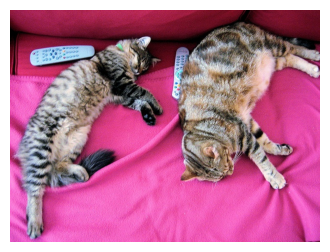

CLIP output (a probability per candidate):
  a photo of a cat     0.9932
  a photo of a dog     0.0050
  a photo of a horse   0.0017

LLaVA output (free text):
Q: What animal is present in the image? Describe its appearance.
A: There is a cat present in the image. The cat is described as being fat and sleeping on a couch.


In [22]:
# Same image for both models: the default cat image
cmp_image = Image.open(IMAGE_PATH).convert("RGB")
cmp_texts = ["a photo of a cat", "a photo of a dog", "a photo of a horse"]
cmp_inputs = processor(text=cmp_texts, images=cmp_image, return_tensors="pt", padding=True)
cmp_inputs = {k: v.to(device) for k, v in cmp_inputs.items()}
with torch.no_grad():
    cmp_probs = model(**cmp_inputs).logits_per_image.softmax(dim=1)[0].cpu()

plt.figure(figsize=(4, 4)); plt.imshow(cmp_image); plt.axis("off"); plt.show()
print("CLIP output (a probability per candidate):")
for t, p in zip(cmp_texts, cmp_probs):
    print(f"  {t:20s} {p:.4f}")

llava_q = "What animal is present in the image? Describe its appearance."
llava_cmp_answer = ask_llava(cmp_image, llava_q)
with open(os.path.join(RESULTS_DIR, "clip_vs_llava.md"), "w", encoding="utf-8") as f:
    f.write(f"# CLIP vs LLaVA on the same image (`{IMAGE_PATH}`)\n\n## CLIP\n\n| Text | Probability |\n|---|---|\n")
    f.write("".join(f"| {t} | {p:.4f} |\n" for t, p in zip(cmp_texts, cmp_probs)))
    f.write(f"\n## LLaVA ({MODEL_ID})\n\n**Q:** {llava_q}\n\n**A:** {llava_cmp_answer}\n")
print(f"\nLLaVA output (free text):\nQ: {llava_q}\nA: {wrap(llava_cmp_answer)}")

### Answers — Exercise 13

| Property | CLIP | LLaVA |
|---|---|---|
| Input | An image **and** a set of candidate texts (or a text query) | An image **and** a free-form text prompt/question |
| Main output | Embeddings and similarity scores (a probability over the given candidates) | Generated natural-language text |
| Zero-shot classification | **Yes**, native: fast, scores over a fixed label set | Possible by asking ("Which animal is this?"), but slower, its output must be parsed, and it gives no calibrated scores |
| Image retrieval | **Yes**: precomputed embeddings, one dot product per image, scales to millions | Not practical: it would have to be run on every image for every query |
| Text generation | No | **Yes** |
| VQA | No; only if each possible answer is written as a candidate text | **Yes** |
| Open-ended response | No; it can only choose among texts it is given | **Yes**: descriptions, explanations, reasoning |

**Our experiment.** On the same image (two cats on a pink sofa):
- **CLIP** returned three numbers: cat **0.993**, dog 0.005, horse 0.002. It is correct and confident, but that is all it can say.
- **LLaVA** answered in free text: *"There is a cat present in the image. The cat is described as being fat and sleeping on a couch."* It adds information CLIP cannot give: the cat is sleeping, on a couch. It also **misses that there are two cats**, a counting/attribute error that has to be caught by a human reader. Asked in the mini-project what "the animals" were doing, it did report two cats, a pink couch and two remote controls. The answer depends on how the question is phrased.

**Q33. Better for image classification?**
**CLIP.** It is purpose-built for scoring an image against a label set, gives comparable scores for every class, is about 100× cheaper per image, and its predictions are deterministic and easy to evaluate.

**Q34. Better for image description?**
**LLaVA.** It generates detailed descriptions covering objects, attributes, counts, the scene and the context. CLIP can only rank captions that someone else wrote.

**Q35. Better for visual question answering?**
**LLaVA.** It accepts arbitrary questions and composes answers. CLIP has no mechanism to read a question and generate an answer.

**Q36. Fundamental difference.**
CLIP is a **discriminative, dual-encoder** model. It encodes image and text *separately* into a shared space and measures how well they match: *"how well does this text match this image?"*. The output is a score.

LLaVA is a **generative** model. It *reuses CLIP's vision encoder*, projects the visual features into an LLM's token space, and lets the LLM *generate* text conditioned on the image and the question: *"what should be said about this image?"*.

So CLIP provides aligned perception, and LLaVA adds language generation and reasoning on top of it. The cost is that LLaVA is much more expensive and can hallucinate, whereas CLIP can only choose among the options it is given.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [23]:
class MultimodalAssistant:
    # Image + Question -> Answer (LLaVA), plus CLIP-powered search over an image collection (bonus).

    def __init__(self, db_paths, db_emb):
        self.db_paths, self.db_emb = db_paths, db_emb

    def ask(self, image, question, history=None):
        if isinstance(image, str):
            image = Image.open(image).convert("RGB")
        return ask_llava(image, question, history=history)

    def describe(self, image):
        return self.ask(image, "Describe this image in detail.")

    def search(self, query, k=3):
        q = clip_text_embeddings([query])
        sims = (self.db_emb @ q.T).squeeze(1).cpu()
        top = sims.topk(min(k, len(sims)))
        return [(self.db_paths[i], float(s)) for i, s in zip(top.indices, top.values)]

    def search_and_explain(self, query, k=3):
        # Bonus: User query -> CLIP Top-K -> LLaVA explanation for each retrieved image
        results = []
        for path, score in self.search(query, k):
            prompt = (f"A user searched an image collection for: \"{query}\". "
                      "Describe this image in one or two sentences, then say whether it matches "
                      "the search and why.")
            results.append({"image": path, "clip_score": round(score, 3), "explanation": self.ask(path, prompt)})
        return results

assistant = MultimodalAssistant(db_paths, db_emb)

# Basic mode: image + question -> answer
demo_q = "What are the animals doing, and what objects are next to them?"
print(f"Q: {demo_q}\nA: {wrap(assistant.ask(IMAGE_PATH, demo_q))}")

Q: What are the animals doing, and what objects are next to them?
A: The animals, two cats, are sleeping or laying down on a pink couch. Next to them, there are two
remote controls, which are likely used for operating a television or other electronic devices. The
presence of the remote controls suggests that the cats might be resting in a living room or a space
where people watch TV or use other electronic devices.


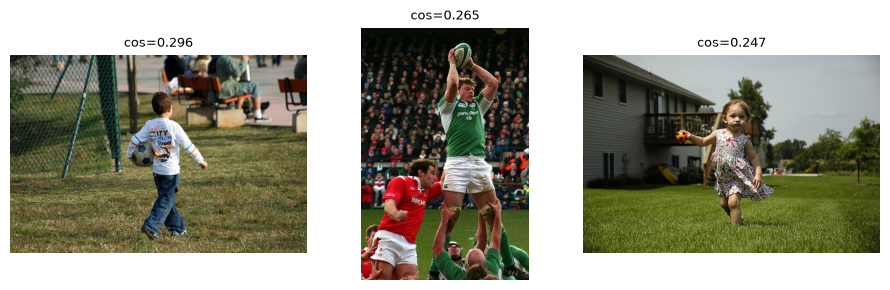

football_02.jpg  (CLIP cosine 0.296)
A young boy is playing with a soccer ball in a field. Yes, it matches the search as the boy is
playing with a soccer ball, which is a common activity in football.

football_03.jpg  (CLIP cosine 0.265)
A man wearing a green and white jersey is jumping in the air to catch a football.

football_01.jpg  (CLIP cosine 0.247)
A little girl is playing with a soccer ball in a yard. Yes, it matches the search as the girl is
playing with a soccer ball, which is a common activity for children.



In [24]:
# Bonus: CLIP retrieval + LLaVA explanation
bonus = assistant.search_and_explain(QUERY, k=3)
show_grid([r["image"] for r in bonus], [f"cos={r['clip_score']}" for r in bonus], ncols=3)
for r in bonus:
    print(f"{os.path.basename(r['image'])}  (CLIP cosine {r['clip_score']})\n{wrap(r['explanation'])}\n")

# Results summary

In [25]:
summary = {
    "CLIP zero-shot accuracy (Ex. 5)": f"{clip_accuracy:.1%} on {len(results_df)} images",
    "Best prompt (Ex. 6)": prompt_df.iloc[0]["prompt"],
    "Top-1 retrieval for the football query (Ex. 8)": f"{os.path.basename(db_paths[top_idx[0]])} (cos {top_scores[0]:.3f})",
    "LLaVA model": MODEL_ID,
    "VQA accuracy (Ex. 11)": f"{vqa_accuracy:.0%}" if vqa_accuracy is not None else "fill human_eval first",
    "Hallucination probe (Ex. 12, 'What color is the bicycle?')": independent[1][1][:120],
}
summary_df = pd.DataFrame(summary.items(), columns=["Item", "Result"])
summary_df.to_csv(os.path.join(RESULTS_DIR, "summary.csv"), index=False)
display(summary_df)
print("Files in results/:", sorted(os.listdir(RESULTS_DIR)))

,Item,Result
0,CLIP zero-shot accuracy (Ex. 5),90.0% on 30 images
1,Best prompt (Ex. 6),a photograph showing a cat
2,Top-1 retrieval for the football query (Ex. 8),football_02.jpg (cos 0.296)
3,LLaVA model,llava-hf/llava-1.5-7b-hf
4,VQA accuracy (Ex. 11),60%
5,"Hallucination probe (Ex. 12, 'What color is the bicycle?')",The bicycle is pink.


Files in results/: ['.gitkeep', 'clip_classification.csv', 'clip_misclassified.png', 'clip_vs_llava.md', 'hallucination_example.md', 'retrieval_top5.csv', 'retrieval_top5.png', 'summary.csv', 'vqa_results.csv']


## Conclusion

This lab compared two ways of connecting vision and language on a local RTX 5070 Ti: CLIP ViT-B/32 in fp32, and LLaVA-1.5-7B in 4-bit, using 5 GB of VRAM.

**CLIP** learns a shared embedding space for images and text through contrastive pre-training. That one mechanism supports both zero-shot classification and label-free retrieval.
- **Classification:** **90% accuracy** (27/30) on CIFAR-10 test images over 6 classes, with no training at all. The three errors were atypical or ambiguous images: two ostrich-like birds and a dark cat on a dark chair. They were also the least confident predictions.
- **Retrieval:** the query "a person playing football" ranked all **four football photos first** among 21 images.
- **Limits:** CLIP can only choose among the candidates it is given. Without "cat" in the list, it labelled the cat photo "car" with p = 0.37. Its scores are also sensitive to the prompt wording: cosine 0.227–0.251 across five phrasings of "cat", although on our small set every template gave the same 90%.

**LLaVA** connects CLIP's vision encoder to a language model through a learned projection. This adds open-ended description and question answering.
- **VQA:** **60% accuracy** (15/25). Counting (5/5) and the main activity (4/5) were reliable. Questions about text (1/5) and location (2/5) were the weakest.
- **Hallucination:** most errors were hallucinations, not misperceptions. The model "read" signs that do not exist in 4 of 5 images. Asked about a bicycle that is not there, it first said correctly that there was none, then gave it a colour (pink, or blue) and a location. An explicit "answer 'There is no bicycle' if there is none" option removed the problem.

**Takeaway.** The two models are complementary. CLIP is cheap, deterministic and well suited to *scoring and searching*. LLaVA is far more expressive but must be checked, because its answers are fluent whether or not they are grounded in the image. The mini-project combines them: CLIP retrieves the top-K images for a query (all three were football photos) and LLaVA explains each result. That retrieve-then-generate design is the basis of multimodal search assistants. It also inherits LLaVA's weakness, so the explanations need the same scepticism as any VQA answer.